# Metropolis-Hastings


In [1]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")

# plt.style.use(
#     "https://github.com/dhaitz/matplotlib-stylesheets/raw/master/pitayasmoothie-dark.mplstyle"
# )

In [2]:
import math

import pandas as pd
import torch
from torch import distributions as dist

## Modelo Poisson-Log Normal

In [3]:
# Parámetro real
lamb = 100.0

# Muestra
n = 100000
x = dist.Poisson(lamb).sample((n,))


def log_posterior(data, lamb, mu=1.0, scale=10.0):

    # Una likelihood para cada cadena
    log_lik = dist.Poisson(lamb[:, None]).log_prob(data).sum(dim=1)

    # Un prior para cada cadena
    log_prior = dist.LogNormal(mu, scale).log_prob(lamb)

    return log_lik + log_prior


# Número de muestras
n_iter = 5000
burn_in = 10000
total_iter = n_iter + burn_in

# Número de cadenas
num_chains = 3

# Estado inicial de cada cadena
lamb_hat = x.mean()

eta_x = torch.log(lamb_hat * torch.ones(num_chains))

# Almacenamiento
eta = torch.empty((n_iter, num_chains))

# Escala de propuesta
s = 1e-4


for i in range(total_iter):

    # Propuesta para cada cadena
    eta_y = eta_x + s * torch.randn(num_chains)

    # Transformación
    lamb_x = torch.exp(eta_x)
    lamb_y = torch.exp(eta_y)

    # Log posterior
    log_ratio = log_posterior(x, lamb_y) - log_posterior(x, lamb_x) + eta_y - eta_x

    # log(alpha)
    log_alpha = torch.minimum(log_ratio, torch.zeros(num_chains))

    # Uniforme independiente para cada cadena
    log_u = torch.log(torch.rand(num_chains))

    # Aceptación independiente
    accept = log_u < log_alpha

    eta_x = torch.where(accept, eta_y, eta_x)

    # Guardar
    if i >= burn_in:
        eta[i - burn_in] = eta_x


# Pasamos de eta a lambda
lamb_samples = torch.exp(eta)

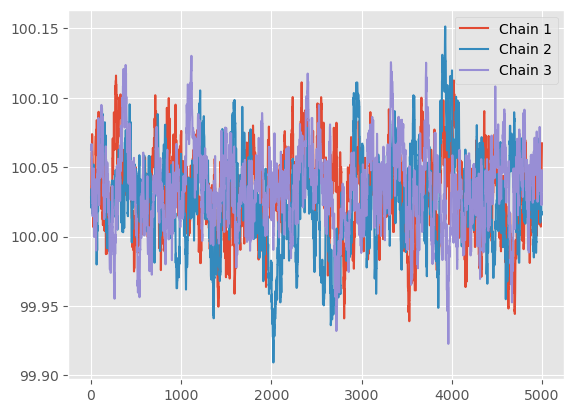

In [32]:
plt.plot(lamb_samples)
plt.legend(["Chain 1", "Chain 2", "Chain 3"])
plt.show()

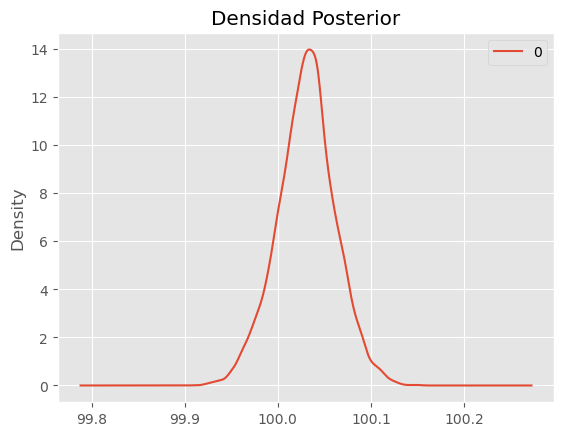

In [33]:
# Densidad Posterior
df_lamb_samples = pd.DataFrame(lamb_samples.flatten())

df_lamb_samples.plot.kde()
plt.title("Densidad Posterior")
plt.show()

In [6]:
# Descripción de la densidad posterior
df_lamb_samples.describe()

,0
count,15000.000000
mean,100.030647
std,0.031515
min,99.909210
25%,100.010925
50%,100.031288
75%,100.050186
max,100.151375


In [7]:
# Intervalo de probabilidad posterior
alpha = 0.01
df_lamb_samples.quantile([alpha / 2, 1 - alpha / 2]).T

,0.005,0.995
0,99.948234,100.112221


## Regresión Logística

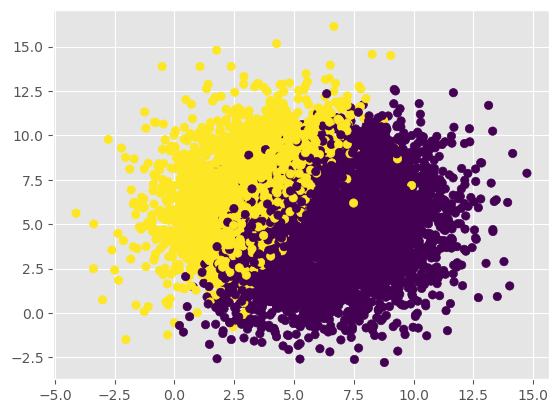

In [34]:
# Parámetros reales

W_real = torch.Tensor([1.2, -1.5, 0.9])

n = 10000
p = 2

# Modelo 
X = 5.5 + 2.5 * torch.randn((n, p))
X_desing = torch.column_stack((torch.ones(n), X))

eta = X_desing @ W_real.T

z = torch.sigmoid(eta)

y = torch.bernoulli(z)


plt.scatter(X_desing[:, 1], X_desing[:, 2], c=y)
plt.show()

In [9]:
def log_posterior(X_desing, y, W, mu=0.0, scale=1.0):

    eta = X_desing @ W

    log_lik = dist.Bernoulli(logits=eta).log_prob(y.view(-1, 1)).sum(dim=0)

    log_prior = dist.Normal(mu, scale).log_prob(W).sum(dim=0)

    return log_lik + log_prior

In [65]:
# Número de muestras
n_iter = 10000
burn_in = 10000
total_iter = n_iter + burn_in

# Número de cadenas
num_chains = 3

# Estado inicial de cada cadena
W_x = torch.randn((p + 1, num_chains))


# Almacenamiento
W = torch.empty((n_iter, p + 1, num_chains))

# Escala de propuesta
s = torch.Tensor([1e-1, 1e-2, 1e-2]).reshape(-1, 1)


accept_count = torch.zeros(num_chains)

for i in range(total_iter):

    W_y = W_x + s * torch.randn((p + 1, num_chains))

    log_ratio = log_posterior(X_desing, y, W_y) - log_posterior(X_desing, y, W_x)

    log_alpha = torch.minimum(log_ratio, torch.zeros(num_chains))

    log_u = torch.log(torch.rand(num_chains))

    accept = log_u < log_alpha

    W_x = torch.where(accept, W_y, W_x)

    if i >= burn_in:
        W[i - burn_in] = W_x
        accept_count += accept

accept_rate = accept_count / n_iter

print(accept_rate)

tensor([0.2997, 0.2959, 0.3030])


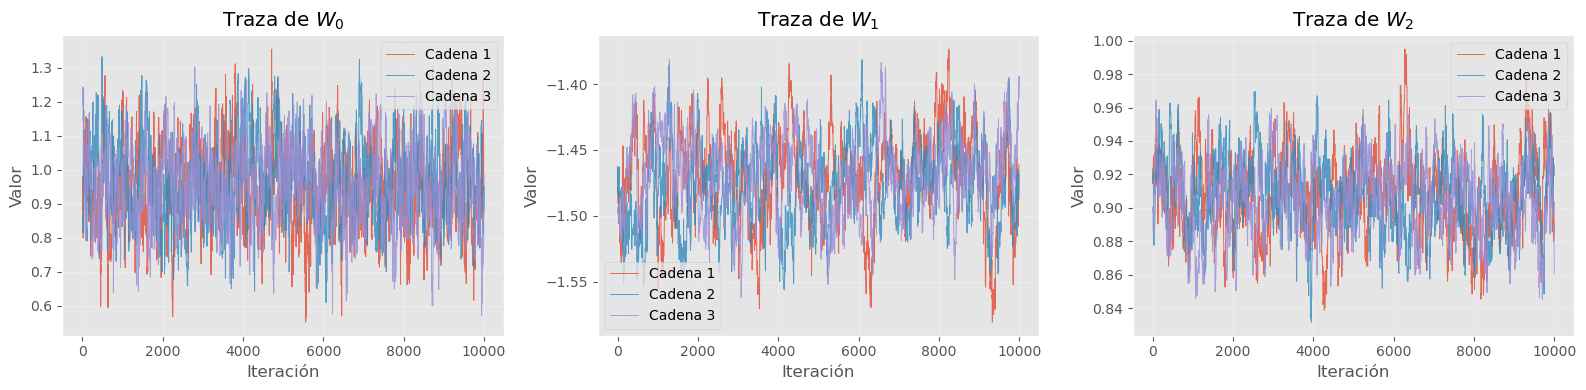

In [66]:
param_names = [f"$W_{j}$" for j in range(p + 1)]

fig, axes = plt.subplots(1, p + 1, figsize=(16, 4))

for j, ax in enumerate(axes):
    # DataFrame: una columna por cadena
    df_trace = pd.DataFrame(
        W[:, j, :], columns=[f"Cadena {c + 1}" for c in range(num_chains)]
    )

    df_trace.plot(ax=ax, linewidth=0.7, alpha=0.8)

    ax.set_title(f"Traza de {param_names[j]}")
    ax.set_xlabel("Iteración")
    ax.set_ylabel("Valor")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

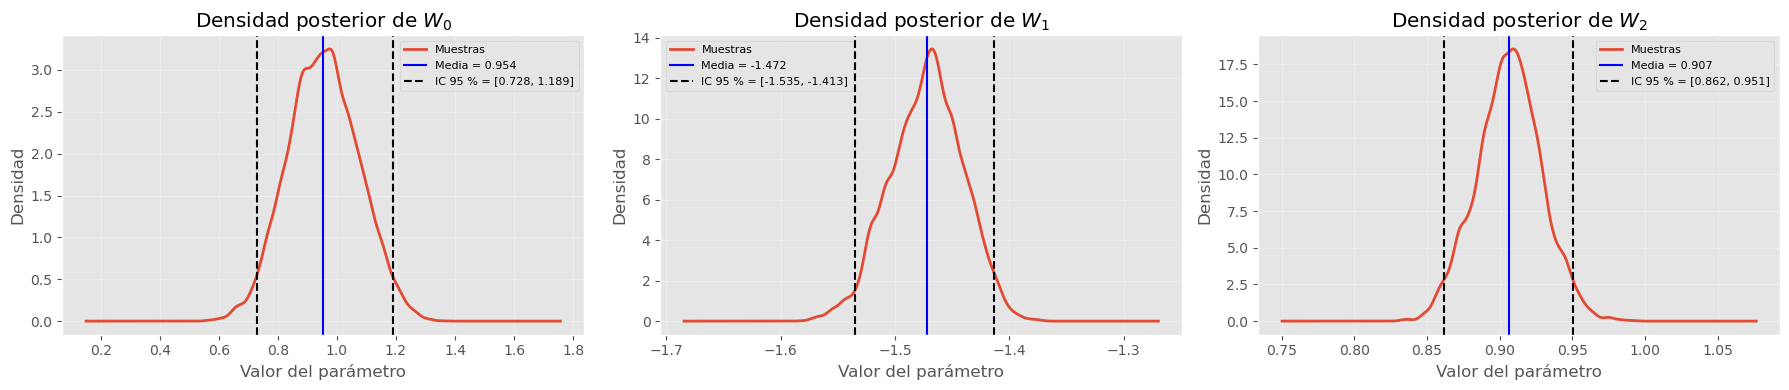

In [67]:
fig, axes = plt.subplots(1, p + 1, figsize=(18, 4))

for j, ax in enumerate(axes):

    # Unir las muestras de las tres cadenas
    muestras = W[:, j, :].reshape(-1)
    df = pd.DataFrame({"Muestras": muestras})

    # Resumen posterior usando pandas
    media = df["Muestras"].mean()
    li = df["Muestras"].quantile(0.025)
    ls = df["Muestras"].quantile(0.975)

    # KDE
    df.plot(kind="density", y="Muestras", ax=ax, legend=False, linewidth=2)

    # Media posterior
    ax.axvline(media, color="blue", linestyle="-", label=f"Media = {media:.3f}")

    # Intervalo de credibilidad del 95 %
    ax.axvline(
        li, color="black", linestyle="--", label=f"IC 95 % = [{li:.3f}, {ls:.3f}]"
    )
    ax.axvline(ls, color="black", linestyle="--")

    ax.set_title(f"Densidad posterior de {param_names[j]}")
    ax.set_xlabel("Valor del parámetro")
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Muestreo de Gibbs

## Modelo Normal-InversaGamma

In [147]:
# Datos del modelo

mu_real = 25
tau_real = 2.5

# datos
n = 10000
y = mu_real + math.sqrt(1 / tau_real) * torch.randn((n,))

In [148]:
def simulate_mu(y, tau, mu_0=0.0, tau_0=0.1):
    n = y.shape[0]
    mu_n = (n * y.mean() + tau_0 * mu_0) / (n + tau_0)
    tau_n = tau * (n + tau_0)
    eps = torch.randn_like(tau)  # misma forma que tau
    return mu_n + torch.sqrt(1.0 / tau_n) * eps


def simulate_tau(y, mu, mu_0=0.0, tau_0=0.1, alpha_0=10.0, beta_0=1.0):
    n = y.shape[0]
    alpha_n = alpha_0 + (n + 1) / 2
    # mu: (num_chains,), y: (n,)
    resid = (y[:, None] - mu[None, :]) ** 2  # (n, num_chains)
    beta_n = beta_0 + 0.5 * resid.sum(dim=0) + 0.5 * tau_0 * (mu - mu_0) ** 2
    return dist.Gamma(alpha_n, beta_n).sample()


# Número de muestras
n_iter = 10000
burn_in = 10000
total_iter = n_iter + burn_in

# Número de cadenas
num_chains = 4

# Estado inicial de cada cadena
mu_x = y.mean().item() * torch.ones(num_chains)
tau_x = y.var().item() * torch.ones(num_chains)

# Almacenamiento
mu = torch.empty((n_iter, num_chains))
tau = torch.empty((n_iter, num_chains))

for i in range(total_iter):

    mu_x = simulate_mu(y, tau_x)
    tau_x = simulate_tau(y, mu_x)

    if i >= burn_in:

        mu[i - burn_in] = mu_x
        tau[i - burn_in] = tau_x

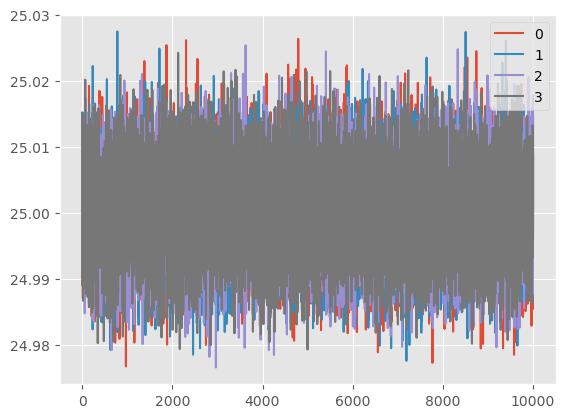

In [149]:
pd.DataFrame(mu).plot()
plt.show()

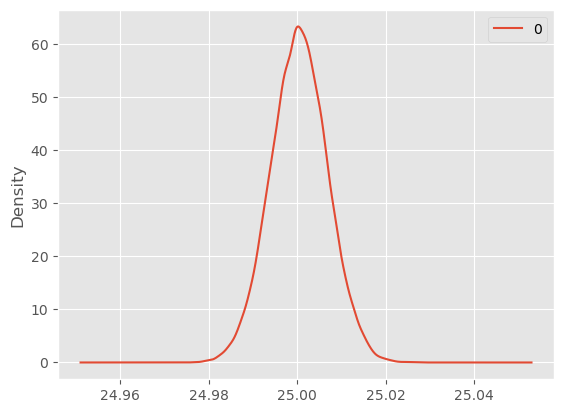

,0
count,40000.000000
mean,25.000456
std,0.006413
min,24.976526
2.5%,24.987785
50%,25.000451
97.5%,25.013094
max,25.027464


In [150]:
pd.DataFrame(mu.flatten()).plot.kde()
plt.show()
pd.DataFrame(mu.flatten()).describe(percentiles=(0.025, 0.975))

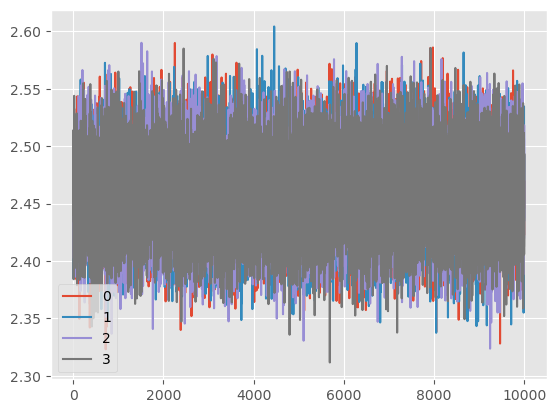

In [151]:
pd.DataFrame(tau).plot()
plt.show()

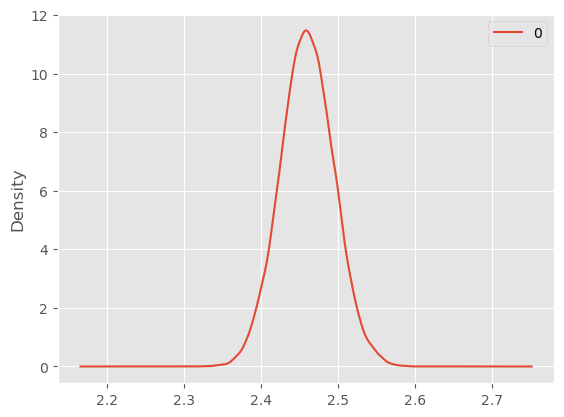

,0
count,40000.000000
mean,2.459384
std,0.034732
min,2.311511
2.5%,2.391350
50%,2.459158
97.5%,2.528061
max,2.604293


In [152]:
pd.DataFrame(tau.flatten()).plot.kde()
plt.show()
pd.DataFrame(tau.flatten()).describe(percentiles=(0.025, 0.975))

## Regresión Probit

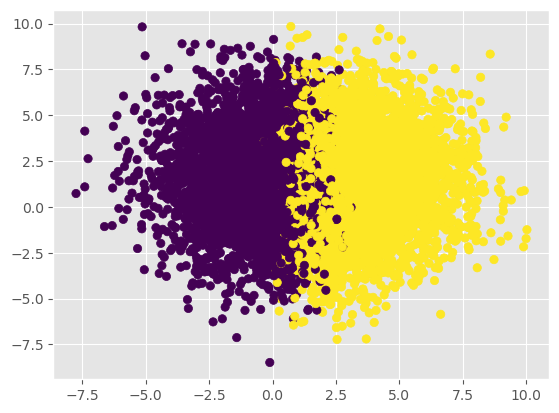

In [24]:
# Parámetros reales

W_real = torch.Tensor([-1.6, 1.25, 0.0])

n = 10000
p = 2


X = 1.5 + 2.5 * torch.randn((n, p))
X_desing = torch.column_stack((torch.ones(n), X))

eta = X_desing @ W_real.T

z = dist.Normal(0, 1).cdf(eta)

y = torch.bernoulli(z)


plt.scatter(X_desing[:, 1], X_desing[:, 2], c=y)
plt.show()

In [32]:
def simulate_W(Z, X_desing, tau=10.0):
    # Z: (num_chains, n)
    # X_desing: (n, p)

    p = X_desing.shape[1]

    sigma_n = torch.linalg.inv(X_desing.T @ X_desing + (1 / tau) * torch.eye(p))

    mu_n = Z @ X_desing @ sigma_n  # (num_chains, p)

    L = torch.linalg.cholesky(sigma_n)

    return mu_n + torch.randn_like(mu_n) @ L.T


def simulate_z(W, y, X_desing):
    # Beta: (num_chains, p)
    # y: (n,)
    # X_desing: (n, p)

    mu = W @ X_desing.T  # (num_chains, n)

    U = torch.rand_like(mu)
    eps = torch.finfo(mu.dtype).eps
    U = U.clamp(eps, 1 - eps)

    # CDF de la normal estándar
    Phi_neg_mu = torch.special.ndtr(-mu)
    Phi_mu = torch.special.ndtr(mu)

    # y = 1: Z truncada a (0, infinito)
    prob_positive = Phi_neg_mu + U * Phi_mu

    # y = 0: Z truncada a (-infinito, 0]
    prob_negative = U * Phi_neg_mu

    # Seleccionar la probabilidad según la etiqueta
    prob = torch.where(y.bool().unsqueeze(0), prob_positive, prob_negative)

    # Inversa de la CDF y transformación a N(mu, 1)
    prob = prob.clamp(eps, 1 - eps)
    Z = mu + torch.special.ndtri(prob)

    return Z


num_chains = 2

# Beta inicial: (num_chains, p)
W_x = torch.zeros((num_chains, X_desing.shape[1]))

# Número de muestras
n_iter = 2000
burn_in = 5000
total_iter = n_iter + burn_in

# Número de cadenas
num_chains = 2


# Almacenamiento
W = torch.empty((n_iter, num_chains, p + 1))

for i in range(total_iter):

    z = simulate_z(W_x, y, X_desing)
    W_x = simulate_W(z, X_desing)

    if i >= burn_in:

        W[i - burn_in] = W_x

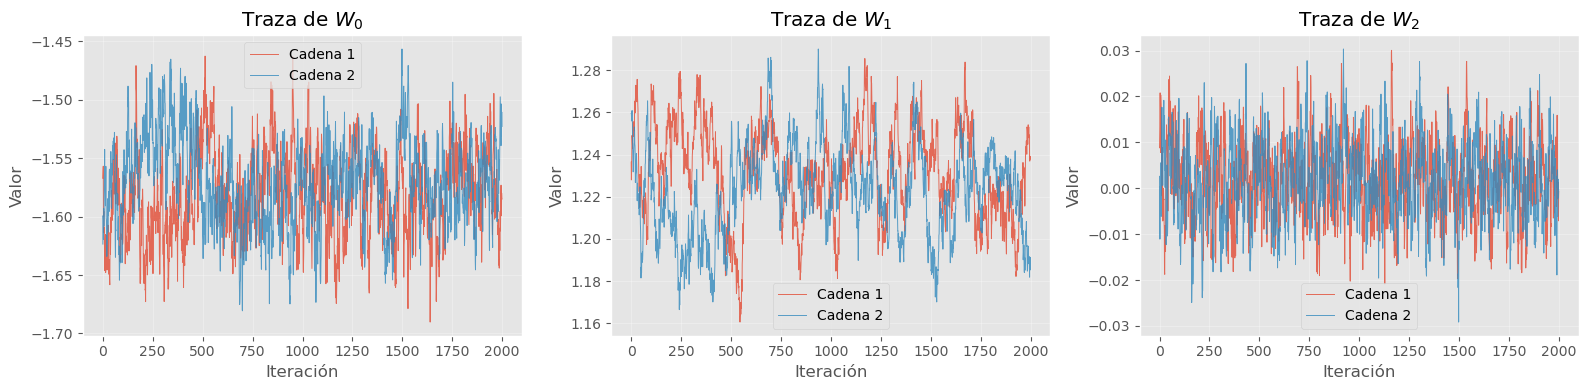

In [33]:
param_names = [f"$W_{j}$" for j in range(p + 1)]

fig, axes = plt.subplots(1, p + 1, figsize=(16, 4))

for j, ax in enumerate(axes):
    # DataFrame: una columna por cadenaile(0.025)
    df_trace = pd.DataFrame(
        W[:, :, j], columns=[f"Cadena {c + 1}" for c in range(num_chains)]
    )

    df_trace.plot(ax=ax, linewidth=0.7, alpha=0.8)

    ax.set_title(f"Traza de {param_names[j]}")
    ax.set_xlabel("Iteración")
    ax.set_ylabel("Valor")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

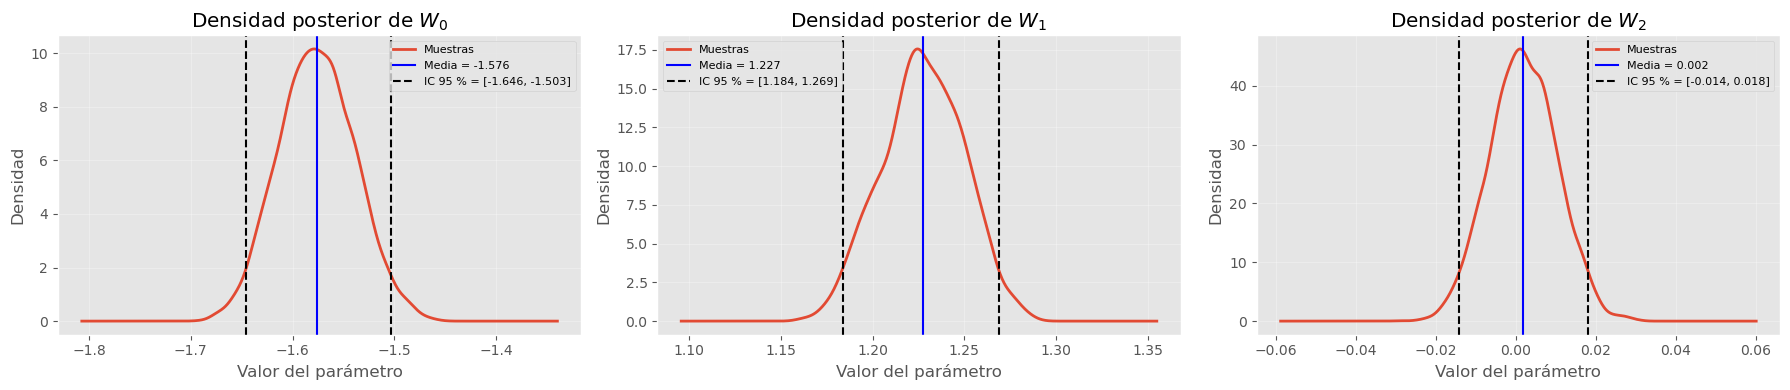

In [34]:
fig, axes = plt.subplots(1, p + 1, figsize=(18, 4))

for j, ax in enumerate(axes):

    # Unir las muestras de las tres cadenas
    muestras = W[:, :, j].reshape(-1)
    df = pd.DataFrame({"Muestras": muestras})

    # Resumen posterior usando pandas
    media = df["Muestras"].mean()
    li = df["Muestras"].quantile(0.025)
    ls = df["Muestras"].quantile(0.975)

    # KDE
    df.plot(kind="density", y="Muestras", ax=ax, legend=False, linewidth=2)

    # Media posterior
    ax.axvline(media, color="blue", linestyle="-", label=f"Media = {media:.3f}")

    # Intervalo de credibilidad del 95 %
    ax.axvline(
        li, color="black", linestyle="--", label=f"IC 95 % = [{li:.3f}, {ls:.3f}]"
    )
    ax.axvline(ls, color="black", linestyle="--")

    ax.set_title(f"Densidad posterior de {param_names[j]}")
    ax.set_xlabel("Valor del parámetro")
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()